# A22 共享人手怎样避免总有人等待别人贡献？

四个团队连续20轮决定是否贡献一人。贡献有个体成本，公共收益由四队共享；比较固定贡献、搭便车、条件合作及事先约定的轮值。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 先写清公共品规则
每队每轮有1单位资源，贡献c_i∈{0,1}后保留1-c_i；公共贡献乘1.6后均分。因此集体贡献有益，但个人在其他人不变时少贡献能获得更多。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

n=4;rounds=20;multiplier=1.6;required=2
def payoffs(contributions,m=multiplier):
    c=np.asarray(contributions,float)
    assert np.all((c==0)|(c==1))
    return 1-c+m*c.sum()/len(c)
assert np.allclose(payoffs([1,1,1,1]),1.6)
assert payoffs([0,1,1,1])[0]>payoffs([1,1,1,1])[0]
rng=np.random.default_rng(22)
# 相同可用性情景供所有规则比较；5%概率该团队本轮无法兑现投入。
availability=rng.random((40,rounds,n))>=.05
rules={"固定贡献":["cooperate"]*4,"各自不贡献":["defect"]*4,
       "条件合作":["conditional"]*4,"混入搭便车":["defect"]+["conditional"]*3,
       "约定轮值":["rotation"]*4}


## 2. 明确策略如何读取历史
条件合作只看上一轮实际贡献率；第一轮合作。轮值每轮安排两队，因此是提前协调的规则，不是个体自发选择的纳什均衡。

In [3]:
def simulate(kinds,available):
    previous=np.ones(len(kinds),int);history=[]
    for t in range(len(available)):
        intended=[]
        for i,kind in enumerate(kinds):
            if kind=="cooperate":choice=1
            elif kind=="defect":choice=0
            elif kind=="conditional":choice=int(previous.mean()>=.75)
            elif kind=="rotation":choice=int(i in {t%len(kinds),(t+1)%len(kinds)})
            else:raise ValueError(kind)
            intended.append(choice)
        actual=np.array(intended,int)*available[t].astype(int)
        rewards=payoffs(actual)
        history.append(dict(round=t,contributions=actual.tolist(),payoffs=rewards.tolist(),
                            contributed=int(actual.sum()),shortage=max(0,required-int(actual.sum()))))
        previous=actual
    return history
experiments={label:[simulate(kinds,a) for a in availability] for label,kinds in rules.items()}


## 3. 用会计恒等式与配对情景检查
每轮总收益应等于N+(乘数-1)×总贡献。对每个规则用同一组40个可用性情景，比较差值而不是挑选一次漂亮结果。

In [4]:
summary=[]
for label,runs in experiments.items():
    total_rewards=[];shortages=[]
    for run in runs:
        for row in run:
            assert np.isclose(sum(row["payoffs"]),n+(multiplier-1)*row["contributed"])
        total_rewards.append(sum(sum(row["payoffs"]) for row in run))
        shortages.append(np.mean([row["shortage"]>0 for row in run]))
    summary.append(dict(rule=label,mean_total_reward=float(np.mean(total_rewards)),
                        reward_sd=float(np.std(total_rewards,ddof=1)),shortage_rate=float(np.mean(shortages))))
table=pd.DataFrame(summary)
assert table.loc[table.rule=="各自不贡献","shortage_rate"].iloc[0]==1


## 4. 看清规则、行为与故障的区别
图展示规则在假设行为和故障机制下的结果。它不能证明人真实一定条件合作，也不能忽略轮值执行所需的协调。缺岗指标是业务结果，博弈收益只是模型内评价。

In [5]:
table.to_csv(OUT_DIR/"合作规则对照.csv",index=False,encoding="utf-8-sig")
pd.DataFrame([dict(rule=label,**row) for label,runs in experiments.items() for row in runs[0]]).to_csv(OUT_DIR/"首个情景逐轮记录.csv",index=False,encoding="utf-8-sig")
for label,runs in experiments.items():
    plt.plot(range(rounds),np.mean([[r["contributed"] for r in run] for run in runs],axis=0),label=label)
plt.axhline(required,color="black",linestyle="--",label="业务需要");plt.xlabel("轮次");plt.ylabel("平均贡献人数");plt.legend(fontsize=8)
plt.tight_layout();plt.savefig(OUT_DIR/"合作演变.png");plt.close()
rotation=table.loc[table.rule=="约定轮值"].iloc[0]
fixed=table.loc[table.rule=="固定贡献"].iloc[0]
save_results({"rules":table.to_dict(orient="records"),"replications":len(availability)},
             f"约定轮值在本情景组中的缺岗比例{rotation.shortage_rate:.1%}，固定全员贡献为{fixed.shortage_rate:.1%}。"
             "轮值节省投入但冗余较少，可研究设置备用人员；条件合作遇到缺席可能连锁退化。"
             "这些是指定策略规则的模拟结果，未声称已经证明重复博弈均衡。")


{
  "rules": [
    {
      "rule": "固定贡献",
      "mean_total_reward": 125.465,
      "reward_sd": 1.1883084292711725,
      "shortage_rate": 0.0
    },
    {
      "rule": "各自不贡献",
      "mean_total_reward": 80.0,
      "reward_sd": 0.0,
      "shortage_rate": 1.0
    },
    {
      "rule": "条件合作",
      "mean_total_reward": 122.345,
      "reward_sd": 7.699215744277016,
      "shortage_rate": 0.06875
    },
    {
      "rule": "混入搭便车",
      "mean_total_reward": 91.22,
      "reward_sd": 8.571006583018933,
      "shortage_rate": 0.6725
    },
    {
      "rule": "约定轮值",
      "mean_total_reward": 102.83000000000001,
      "reward_sd": 0.8800349643403611,
      "shortage_rate": 0.0975
    }
  ],
  "replications": 40
}
约定轮值在本情景组中的缺岗比例9.8%，固定全员贡献为0.0%。轮值节省投入但冗余较少，可研究设置备用人员；条件合作遇到缺席可能连锁退化。这些是指定策略规则的模拟结果，未声称已经证明重复博弈均衡。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

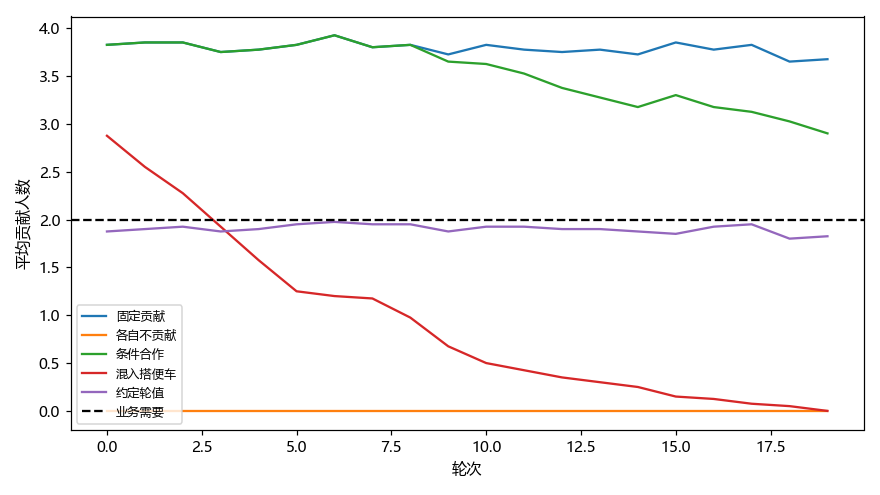

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
本例是重复公共品中的指定策略比较，不是联盟价值合作博弈，也未求子博弈精炼均衡。条件合作阈值、乘数、缺席率均为教学假设。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。